# ЛР1. Предобработка данных

**Датасет:** Credit Score Classification  
**Выполнил(а):** Быков Лев

**Группа:** P3319

## 0. Постановка задачи

### 1. Датасет

Набор содержит помесячные финансовые сведения о клиентах банка. В архиве две таблицы:

- `train.csv` — январь–август, 100 000 наблюдений и целевая переменная `Credit_Score`;
- `test.csv` — сентябрь–декабрь, 50 000 наблюдений без целевой переменной;
- один клиент встречается несколько раз, поэтому единица наблюдения — **клиент в конкретном месяце**;
- целевой класс принимает значения `Good`, `Standard`, `Poor`.

Признаки описывают доход, кредитную нагрузку, задержки платежей, кредитную историю, поведение при оплате и остаток средств.

### 2. Цель

Подготовить согласованный набор данных для последующей классификации кредитного рейтинга: выявить пропуски и технические маркеры, исправить типы, обработать аномалии, восстановить стабильные характеристики клиента и создать интерпретируемые признаки.

### 3. Задачи

1. Изучить структуру `train` и `test`, типы, пропуски, дубликаты и баланс классов.
2. Найти неявные пропуски и значения, нарушающие предметные ограничения.
3. Использовать повторные наблюдения клиента для восстановления стабильных признаков.
4. Обработать меняющиеся во времени признаки без использования целевой переменной.
5. Удалить персональные и технические поля, сформировать дополнительные категории.
6. Проверить результат и сохранить очищенные таблицы.

### 4. Гипотезы для дальнейшего анализа

1. Больший долг и более длительные просрочки связаны с худшим `Credit_Score`.
2. Высокая процентная ставка чаще встречается у клиентов с рейтингом `Poor`.
3. Категория `Credit_Mix = Bad` связана с худшим рейтингом.
4. Частые кредитные запросы связаны с ухудшением рейтинга.
5. Большая доля EMI-платежей в месячном доходе связана с худшим рейтингом.

Это наблюдательные гипотезы: обнаруженная связь сама по себе не доказывает причинность.

## Установка необходимых библиотек

Перед первым запуском проверим окружение. Если нужных библиотек нет, следующая ячейка установит их в текущий Python-интерпретатор. Уже установленные пакеты повторно не загружаются.

## 1. Обзор данных

Загружаем обе таблицы прямо из `archive.zip`, который лежит в одной папке с ноутбуком (`dataset-intro`). Дополнительный путь `dataset-intro/archive.zip` позволяет запускать ноутбук и из корня проекта.

In [3]:
from pathlib import Path
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
plt.style.use("seaborn-v0_8-whitegrid")

candidates = [
    Path("archive.zip"),
    Path("dataset-intro") / "archive.zip",
]
archive_path = next((p for p in candidates if p.exists()), None)
if archive_path is None:
    raise FileNotFoundError("Поместите archive.zip в папку dataset-intro рядом с ноутбуком")

with zipfile.ZipFile(archive_path) as archive:
    train_raw = pd.read_csv(archive.open("train.csv"), low_memory=False)
    test_raw = pd.read_csv(archive.open("test.csv"), low_memory=False)

print("Архив:", archive_path.resolve())
print("train:", train_raw.shape, "test:", test_raw.shape)

Архив: /home/undndnwnkk/dev/university-works/data-analysis-3rd-course/dataset-intro/archive.zip
train: (100000, 28) test: (50000, 27)


### 1.1. Словарь основных признаков

| Признак | Смысл |
|---|---|
| `Customer_ID`, `Month` | клиент и месяц наблюдения |
| `Age`, `Occupation`, `Annual_Income` | возраст, профессия, годовой доход |
| `Monthly_Inhand_Salary` | ежемесячный доход после удержаний |
| `Num_Bank_Accounts`, `Num_Credit_Card` | количество счетов и кредитных карт |
| `Interest_Rate`, `Num_of_Loan`, `Type_of_Loan` | ставка, число и типы кредитов |
| `Delay_from_due_date`, `Num_of_Delayed_Payment` | просрочка и число задержанных платежей |
| `Outstanding_Debt` | непогашенная задолженность |
| `Credit_Utilization_Ratio` | доля использования кредитного лимита |
| `Credit_History_Age` | длительность кредитной истории |
| `Total_EMI_per_month` | ежемесячные платежи по кредитам |
| `Amount_invested_monthly`, `Monthly_Balance` | инвестиции и остаток за месяц |
| `Payment_Behaviour` | сочетание уровня трат и размера платежей |
| `Credit_Score` | целевой кредитный рейтинг |

In [2]:
train_raw.head(10)

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,11.27,4.0,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",-1,NaN,11.27,4.0,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,_,4.0,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5,4,6.27,4.0,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6,NaN,11.27,4.0,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good
5,0x1607,CUS_0xd40,June,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",8,4,9.27,4.0,Good,809.98,27.262259,22 Years and 6 Months,No,49.574949,62.430172331195294,!@9#%8,340.4792117872438,Good
6,0x1608,CUS_0xd40,July,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,8_,11.27,4.0,Good,809.98,22.537593,22 Years and 7 Months,No,49.574949,178.3440674122349,Low_spent_Small_value_payments,244.5653167062043,Good
7,0x1609,CUS_0xd40,August,NaN,23,#F%$D@*&8,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,6,11.27,4.0,Good,809.98,23.933795,NaN,No,49.574949,24.785216509052056,High_spent_Medium_value_payments,358.12416760938714,Standard
8,0x160e,CUS_0x21b1,January,Rick Rothackerj,28_,004-07-5839,_______,34847.84,3037.986667,2,4,6,1,Credit-Builder Loan,3,4,5.42,2.0,Good,605.03,24.464031,26 Years and 7 Months,No,18.816215,104.291825168246,Low_spent_Small_value_payments,470.69062692529184,Standard
9,0x160f,CUS_0x21b1,February,Rick Rothackerj,28,004-07-5839,Teacher,34847.84,3037.986667,2,4,6,1,Credit-Builder Loan,7,1,7.42,2.0,Good,605.03,38.550848,26 Years and 8 Months,No,18.816215,40.39123782853101,High_spent_Large_value_payments,484.5912142650067,Good


In [4]:
overview = pd.DataFrame({
    "train_type": train_raw.dtypes.astype(str),
    "train_non_null": train_raw.notna().sum(),
    "train_unique": train_raw.nunique(dropna=True),
    "test_type": test_raw.dtypes.astype(str),
    "test_non_null": test_raw.notna().sum(),
    "test_unique": test_raw.nunique(dropna=True),
})
overview

,train_type,train_non_null,train_unique,test_type,test_non_null,test_unique
Age,str,100000,1788,str,50000.0,976.0
Amount_invested_monthly,str,95521,91049,str,47729.0,45450.0
Annual_Income,str,100000,18940,str,50000.0,16121.0
Changed_Credit_Limit,str,100000,4384,str,50000.0,3927.0
Credit_History_Age,str,90970,404,str,45530.0,399.0
Credit_Mix,str,100000,4,str,50000.0,4.0
Credit_Score,str,100000,3,NaN,NaN,NaN
Credit_Utilization_Ratio,float64,100000,100000,float64,50000.0,50000.0
Customer_ID,str,100000,12500,str,50000.0,12500.0
Delay_from_due_date,int64,100000,73,int64,50000.0,73.0


In [4]:
missing = pd.DataFrame({
    "train_missing": train_raw.isna().sum(),
    "train_missing_%": train_raw.isna().mean().mul(100).round(2),
    "test_missing": test_raw.isna().sum(),
    "test_missing_%": test_raw.isna().mean().mul(100).round(2),
}).sort_values("train_missing", ascending=False)
missing[missing.max(axis=1) > 0]

,train_missing,train_missing_%,test_missing,test_missing_%
Monthly_Inhand_Salary,15002,15.00,7498.0,15.00
Type_of_Loan,11408,11.41,5704.0,11.41
Name,9985,9.98,5015.0,10.03
Credit_History_Age,9030,9.03,4470.0,8.94
Num_of_Delayed_Payment,7002,7.00,3498.0,7.00
Amount_invested_monthly,4479,4.48,2271.0,4.54
Num_Credit_Inquiries,1965,1.96,1035.0,2.07
Monthly_Balance,1200,1.20,562.0,1.12


In [5]:
print("Полных дублей train:", train_raw.duplicated().sum())
print("Полных дублей test:", test_raw.duplicated().sum())
print("Уникальных ID train:", train_raw["ID"].nunique())
print("Уникальных клиентов train:", train_raw["Customer_ID"].nunique())
print("Уникальных клиентов test:", test_raw["Customer_ID"].nunique())
print("Клиентов только в test:", len(set(test_raw["Customer_ID"]) - set(train_raw["Customer_ID"])))
print("\nЧисло строк на клиента в train:")
print(train_raw.groupby("Customer_ID").size().value_counts().sort_index())

Полных дублей train: 0
Полных дублей test: 0
Уникальных ID train: 100000
Уникальных клиентов train: 12500
Уникальных клиентов test: 12500
Клиентов только в test: 0

Число строк на клиента в train:
8    12500
Name: count, dtype: int64


,наблюдений,"доля, %"
Credit_Score,,
Standard,53174,53.17
Poor,28998,29.00
Good,17828,17.83


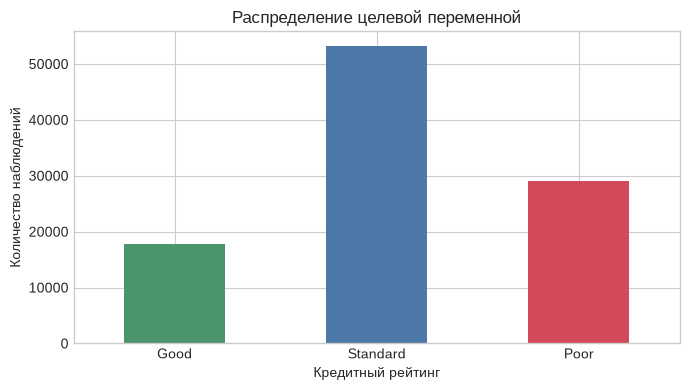

In [6]:
target_counts = train_raw["Credit_Score"].value_counts()
target_share = train_raw["Credit_Score"].value_counts(normalize=True).mul(100).round(2)
display(pd.DataFrame({"наблюдений": target_counts, "доля, %": target_share}))

ax = target_counts.reindex(["Good", "Standard", "Poor"]).plot(
    kind="bar", color=["#4c956c", "#4c78a8", "#d1495b"], figsize=(7, 4)
)
ax.set_title("Распределение целевой переменной")
ax.set_xlabel("Кредитный рейтинг")
ax.set_ylabel("Количество наблюдений")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### 1.2. Неявные пропуски и повреждённые значения

Обычный `isna()` не видит служебные маркеры. Проверим строки с подчёркиваниями и известные бессмысленные категории. Подчёркивание внутри `Customer_ID` и названий вроде `Media_Manager` является частью корректного значения, поэтому учитываем контекст каждого поля.

In [7]:
technical_markers = {
    "Occupation": ["_______"],
    "Credit_Mix": ["_"],
    "Changed_Credit_Limit": ["_"],
    "Payment_Behaviour": ["!@9#%8"],
    "SSN": ["#F%$D@*&8"],
}

marker_rows = []
for column, markers in technical_markers.items():
    marker_rows.append({
        "признак": column,
        "маркеры": ", ".join(markers),
        "train": train_raw[column].isin(markers).sum(),
        "test": test_raw[column].isin(markers).sum(),
    })

suffix_columns = [
    "Age", "Annual_Income", "Num_of_Loan", "Num_of_Delayed_Payment",
    "Outstanding_Debt", "Amount_invested_monthly", "Monthly_Balance",
]
for column in suffix_columns:
    marker_rows.append({
        "признак": column,
        "маркеры": "число с суффиксом _",
        "train": train_raw[column].astype("string").str.endswith("_", na=False).sum(),
        "test": test_raw[column].astype("string").str.endswith("_", na=False).sum(),
    })

pd.DataFrame(marker_rows)

,признак,маркеры,train,test
0,Occupation,_______,7062,3438
1,Credit_Mix,_,20195,9805
2,Changed_Credit_Limit,_,2091,1059
3,Payment_Behaviour,!@9#%8,7600,3800
4,SSN,#F%$D@*&8,5572,2828
5,Age,число с суффиксом _,4939,2477
6,Annual_Income,число с суффиксом _,6980,3520
7,Num_of_Loan,число с суффиксом _,4785,2436
8,Num_of_Delayed_Payment,число с суффиксом _,2744,1427
9,Outstanding_Debt,число с суффиксом _,1009,491


In [8]:
raw_numeric_columns = [
    "Age", "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts",
    "Num_Credit_Card", "Interest_Rate", "Num_of_Loan", "Delay_from_due_date",
    "Num_of_Delayed_Payment", "Changed_Credit_Limit", "Num_Credit_Inquiries",
    "Outstanding_Debt", "Credit_Utilization_Ratio", "Total_EMI_per_month",
    "Amount_invested_monthly", "Monthly_Balance",
]

def numeric_view(series):
    return pd.to_numeric(
        series.astype("string").str.replace("_", "", regex=False), errors="coerce"
    )

raw_ranges = []
for column in raw_numeric_columns:
    values = numeric_view(train_raw[column])
    raw_ranges.append({
        "признак": column,
        "пропусков после преобразования": values.isna().sum(),
        "min": values.min(),
        "медиана": values.median(),
        "p99": values.quantile(0.99),
        "max": values.max(),
    })
pd.DataFrame(raw_ranges).set_index("признак").round(2)

,пропусков после преобразования,min,медиана,p99,max
признак,,,,,
Age,0,-5.000000e+02,33.00,4112.07,8698.00
Annual_Income,0,7.005930e+03,37578.61,179987.28,24198062.00
Monthly_Inhand_Salary,15002,3.036500e+02,3093.75,13814.93,15204.63
Num_Bank_Accounts,0,-1.000000e+00,6.00,445.01,1798.00
Num_Credit_Card,0,0.000000e+00,5.00,849.00,1499.00
Interest_Rate,0,1.000000e+00,13.00,2865.01,5797.00
Num_of_Loan,0,-1.000000e+02,3.00,9.00,1496.00
Delay_from_due_date,0,-5.000000e+00,18.00,61.00,67.00
Num_of_Delayed_Payment,7002,-3.000000e+00,14.00,27.00,4397.00


### Наблюдения по исходным данным

- `train` содержит 100 000 строк и 28 полей, `test` — 50 000 строк и 27 полей.
- 12 500 клиентов представлены ровно восемью месяцами в `train` и четырьмя в `test`; это позволяет восстанавливать стабильные признаки по клиенту.
- Полных дублей нет, `ID` уникален.
- Цель несбалансирована умеренно: `Standard` — 53.17%, `Poor` — 29.00%, `Good` — 17.83%.
- Помимо обычных пропусков есть технические маркеры `_`, `_______`, `!@9#%8`, числовые строки с завершающим `_`.
- Диапазоны показывают ошибки ввода: возраст `-500` и тысячи лет, сотни счетов/карт, огромные ставки, EMI и отрицательный остаток порядка $10^{26}$.
- Поля `Name` и `SSN` содержат персональные данные и не нужны для модели; `ID` — технический идентификатор.

## 2. Предобработка

### 2.1. Стратегия

Предобработка разделена на два этапа.

1. **Базовая очистка:** технические маркеры заменяются на `NaN`, числовые строки переводятся в числа, кредитная история — в месяцы, невозможные значения отбрасываются.
2. **Восстановление:** стабильные признаки берутся как наиболее частое корректное значение того же клиента в `train`; меняющиеся показатели заполняются медианой клиента из `train`, затем медианой/модой всего `train`.

Целевая переменная при заполнении не используется. Профили строятся только по обучающей части, поэтому информация из `test` не влияет на подготовку `train`.

In [9]:
MONTH_NUMBER = {
    "January": 1, "February": 2, "March": 3, "April": 4,
    "May": 5, "June": 6, "July": 7, "August": 8,
    "September": 9, "October": 10, "November": 11, "December": 12,
}

NUMERIC_COLUMNS = [
    "Age", "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts",
    "Num_Credit_Card", "Interest_Rate", "Num_of_Loan", "Delay_from_due_date",
    "Num_of_Delayed_Payment", "Changed_Credit_Limit", "Num_Credit_Inquiries",
    "Outstanding_Debt", "Credit_Utilization_Ratio", "Total_EMI_per_month",
    "Amount_invested_monthly", "Monthly_Balance",
]

VALID_RANGES = {
    "Age": (14, 100),
    "Annual_Income": (1, 1_000_000),
    "Monthly_Inhand_Salary": (0, 100_000),
    "Num_Bank_Accounts": (0, 20),
    "Num_Credit_Card": (0, 20),
    "Interest_Rate": (0, 50),
    "Num_of_Loan": (0, 20),
    "Num_of_Delayed_Payment": (0, 100),
    "Changed_Credit_Limit": (-10, 50),
    "Num_Credit_Inquiries": (0, 50),
    "Outstanding_Debt": (0, 100_000),
    "Credit_Utilization_Ratio": (0, 100),
    "Total_EMI_per_month": (0, 100_000),
    "Amount_invested_monthly": (0, 9_999.99),
    "Monthly_Balance": (0, 1_000_000),
}

def parse_history_months(series):
    text = series.astype("string")
    years = pd.to_numeric(text.str.extract(r"(\d+)\s+Years", expand=False), errors="coerce")
    months = pd.to_numeric(text.str.extract(r"(\d+)\s+Months", expand=False), errors="coerce")
    return years * 12 + months

def basic_clean(frame):
    result = frame.copy()

    for column in result.select_dtypes(include=["object", "string"]).columns:
        result[column] = result[column].astype("string").str.strip()

    result["Occupation"] = result["Occupation"].replace("_______", pd.NA)
    result["Credit_Mix"] = result["Credit_Mix"].replace("_", pd.NA)
    result["Payment_Behaviour"] = result["Payment_Behaviour"].replace("!@9#%8", pd.NA)

    for column in NUMERIC_COLUMNS:
        result[column] = pd.to_numeric(
            result[column].astype("string").str.replace("_", "", regex=False),
            errors="coerce",
        ).astype("float64")

    result["Credit_History_Months_raw"] = parse_history_months(result["Credit_History_Age"])
    result["Month_Number"] = result["Month"].map(MONTH_NUMBER)

    for column, (lower, upper) in VALID_RANGES.items():
        result.loc[~result[column].between(lower, upper), column] = np.nan

    # Отрицательная просрочка означает оплату до срока: для шкалы риска это 0 дней просрочки.
    result["Delay_from_due_date"] = result["Delay_from_due_date"].clip(lower=0)

    # Значение 10000 в инвестициях — известная числовая заглушка и исключено границей выше.
    return result

train_stage = basic_clean(train_raw)
test_stage = basic_clean(test_raw)

### 2.2. Стабильные признаки клиента

Возраст, профессия, доход, число счетов/карт, ставка, кредиты и долг не должны случайно меняться каждый месяц. После удаления невозможных значений заменяем их модой клиента в `train`. Для числовых полей при равенстве частот берётся медиана кандидатов. Такой подход устойчив к одиночным повреждениям и использует структуру панели данных.

In [10]:
STABLE_NUMERIC = [
    "Age", "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts",
    "Num_Credit_Card", "Interest_Rate", "Num_of_Loan", "Outstanding_Debt",
]
STABLE_CATEGORICAL = ["Occupation", "Type_of_Loan", "Credit_Mix"]

def numeric_mode(series):
    values = series.dropna()
    if values.empty:
        return np.nan
    modes = values.mode()
    return float(modes.median())

def categorical_mode(series):
    values = series.dropna()
    if values.empty:
        return pd.NA
    return values.mode().iloc[0]

numeric_profile = train_stage.groupby("Customer_ID")[STABLE_NUMERIC].agg(numeric_mode)
categorical_profile = train_stage.groupby("Customer_ID")[STABLE_CATEGORICAL].agg(categorical_mode)

global_numeric = train_stage[STABLE_NUMERIC].median()
global_categorical = {
    column: categorical_mode(train_stage[column]) for column in STABLE_CATEGORICAL
}

def apply_stable_profile(frame):
    result = frame.copy()
    for column in STABLE_NUMERIC:
        mapped = result["Customer_ID"].map(numeric_profile[column])
        result[column] = mapped.fillna(global_numeric[column])
    for column in STABLE_CATEGORICAL:
        mapped = result["Customer_ID"].map(categorical_profile[column])
        result[column] = mapped.fillna(global_categorical[column])

    no_loan = result["Num_of_Loan"].eq(0)
    result.loc[no_loan, "Type_of_Loan"] = "No Loan"
    return result

train_clean = apply_stable_profile(train_stage)
test_clean = apply_stable_profile(test_stage)

print("Пропуски после восстановления стабильных признаков:")
display(train_clean[STABLE_NUMERIC + STABLE_CATEGORICAL].isna().sum().to_frame("train"))

Пропуски после восстановления стабильных признаков:


,train
Age,0
Annual_Income,0
Monthly_Inhand_Salary,0
Num_Bank_Accounts,0
Num_Credit_Card,0
Interest_Rate,0
Num_of_Loan,0
Outstanding_Debt,0
Occupation,0
Type_of_Loan,0


### 2.3. Кредитная история и меняющиеся признаки

`Credit_History_Age` записан строкой (`22 Years and 3 Months`). Переводим его в число месяцев. Для каждого клиента оцениваем базовую длительность как `история − номер месяца`, поэтому пропуск восстанавливается с сохранением ежемесячного роста.

Остальные месячные числовые признаки заполняются медианой клиента из `train`, затем общей медианой `train`. Категориальное платёжное поведение — модой клиента, затем общей модой. Это лучше среднего для асимметричных финансовых распределений.

In [11]:
# Базовая длина кредитной истории до начала календарного года.
history_base = (
    train_stage["Credit_History_Months_raw"] - train_stage["Month_Number"]
).groupby(train_stage["Customer_ID"]).median()
global_history_base = (
    train_stage["Credit_History_Months_raw"] - train_stage["Month_Number"]
).median()

def restore_history(frame):
    result = frame.copy()
    base = result["Customer_ID"].map(history_base).fillna(global_history_base)
    result["Credit_History_Months"] = (base + result["Month_Number"]).round()
    return result

train_clean = restore_history(train_clean)
test_clean = restore_history(test_clean)

MONTHLY_NUMERIC = [
    "Delay_from_due_date", "Num_of_Delayed_Payment", "Changed_Credit_Limit",
    "Num_Credit_Inquiries", "Credit_Utilization_Ratio", "Total_EMI_per_month",
    "Amount_invested_monthly", "Monthly_Balance",
]
MONTHLY_CATEGORICAL = ["Payment_of_Min_Amount", "Payment_Behaviour"]

# EMI намного выше доступного месячного дохода считаем повреждением.
for frame in (train_clean, test_clean):
    impossible_emi = frame["Total_EMI_per_month"] > frame["Monthly_Inhand_Salary"] * 1.5
    frame.loc[impossible_emi, "Total_EMI_per_month"] = np.nan

monthly_numeric_profile = train_clean.groupby("Customer_ID")[MONTHLY_NUMERIC].median()
monthly_categorical_profile = train_clean.groupby("Customer_ID")[MONTHLY_CATEGORICAL].agg(categorical_mode)
monthly_global_median = train_clean[MONTHLY_NUMERIC].median()
monthly_global_mode = {
    column: categorical_mode(train_clean[column]) for column in MONTHLY_CATEGORICAL
}

def fill_monthly(frame):
    result = frame.copy()
    for column in MONTHLY_NUMERIC:
        result[column] = result[column].fillna(result["Customer_ID"].map(monthly_numeric_profile[column]))
        result[column] = result[column].fillna(monthly_global_median[column])
    for column in MONTHLY_CATEGORICAL:
        result[column] = result[column].fillna(result["Customer_ID"].map(monthly_categorical_profile[column]))
        result[column] = result[column].fillna(monthly_global_mode[column])
    return result

train_clean = fill_monthly(train_clean)
test_clean = fill_monthly(test_clean)

### 2.4. Удаление полей и создание признаков

- `Name` и `SSN` удаляются как персональные данные и потенциальный источник переобучения.
- `ID` сохраняется только для связи с исходной записью; перед обучением модели его нужно исключить из матрицы признаков.
- Исходная строка `Credit_History_Age` заменяется числом месяцев.
- Добавляются доли долговой нагрузки, возрастная группа и интервалы просрочки.

In [12]:
def add_features_and_finalize(frame):
    result = frame.copy()

    result["Debt_to_Annual_Income"] = result["Outstanding_Debt"] / result["Annual_Income"]
    result["EMI_to_Monthly_Income"] = result["Total_EMI_per_month"] / result["Monthly_Inhand_Salary"]
    result["Investment_to_Monthly_Income"] = result["Amount_invested_monthly"] / result["Monthly_Inhand_Salary"]

    result["Age_Group"] = pd.cut(
        result["Age"], bins=[13, 24, 34, 44, 54, np.inf],
        labels=["14–24", "25–34", "35–44", "45–54", "55+"],
    )
    result["Delay_Band"] = pd.cut(
        result["Delay_from_due_date"], bins=[-0.01, 0, 15, 30, np.inf],
        labels=["без просрочки", "1–15 дней", "16–30 дней", "31+ дней"],
    )

    integer_columns = [
        "Age", "Num_Bank_Accounts", "Num_Credit_Card", "Interest_Rate",
        "Num_of_Loan", "Delay_from_due_date", "Num_of_Delayed_Payment",
        "Num_Credit_Inquiries", "Month_Number", "Credit_History_Months",
    ]
    for column in integer_columns:
        result[column] = result[column].round().astype("int64")

    result = result.drop(columns=[
        "Name", "SSN", "Credit_History_Age", "Credit_History_Months_raw",
    ])
    return result

train_clean = add_features_and_finalize(train_clean)
test_clean = add_features_and_finalize(test_clean)

print("train после очистки:", train_clean.shape)
print("test после очистки:", test_clean.shape)

train после очистки: (100000, 32)
test после очистки: (50000, 31)


### 2.5. Проверка результата

Проверяем отсутствие пропусков и дублей, совпадение набора признаков `train`/`test`, допустимые диапазоны и сохранение числа строк.

In [13]:
checks = {
    "число строк train сохранено": len(train_clean) == len(train_raw),
    "число строк test сохранено": len(test_clean) == len(test_raw),
    "пропусков train нет": train_clean.isna().sum().sum() == 0,
    "пропусков test нет": test_clean.isna().sum().sum() == 0,
    "полных дублей train нет": train_clean.duplicated().sum() == 0,
    "полных дублей test нет": test_clean.duplicated().sum() == 0,
    "набор признаков совпадает": set(train_clean.drop(columns="Credit_Score")) == set(test_clean),
    "возраст допустим": train_clean["Age"].between(14, 100).all(),
    "счета допустимы": train_clean["Num_Bank_Accounts"].between(0, 20).all(),
    "карты допустимы": train_clean["Num_Credit_Card"].between(0, 20).all(),
    "ставка допустима": train_clean["Interest_Rate"].between(0, 50).all(),
    "остаток неотрицательный": train_clean["Monthly_Balance"].ge(0).all(),
}
pd.Series(checks, name="результат").to_frame()

,результат
число строк train сохранено,True
число строк test сохранено,True
пропусков train нет,True
пропусков test нет,True
полных дублей train нет,True
полных дублей test нет,True
набор признаков совпадает,True
возраст допустим,True
счета допустимы,True
карты допустимы,True


In [14]:
final_schema = pd.DataFrame({
    "тип": train_clean.dtypes.astype(str),
    "непустых": train_clean.notna().sum(),
    "уникальных": train_clean.nunique(dropna=True),
})
final_schema

,тип,непустых,уникальных
ID,string,100000,100000
Customer_ID,string,100000,12500
Month,string,100000,8
Age,int64,100000,43
Occupation,string,100000,15
Annual_Income,float64,100000,12488
Monthly_Inhand_Salary,float64,100000,12489
Num_Bank_Accounts,int64,100000,11
Num_Credit_Card,int64,100000,12
Interest_Rate,int64,100000,34


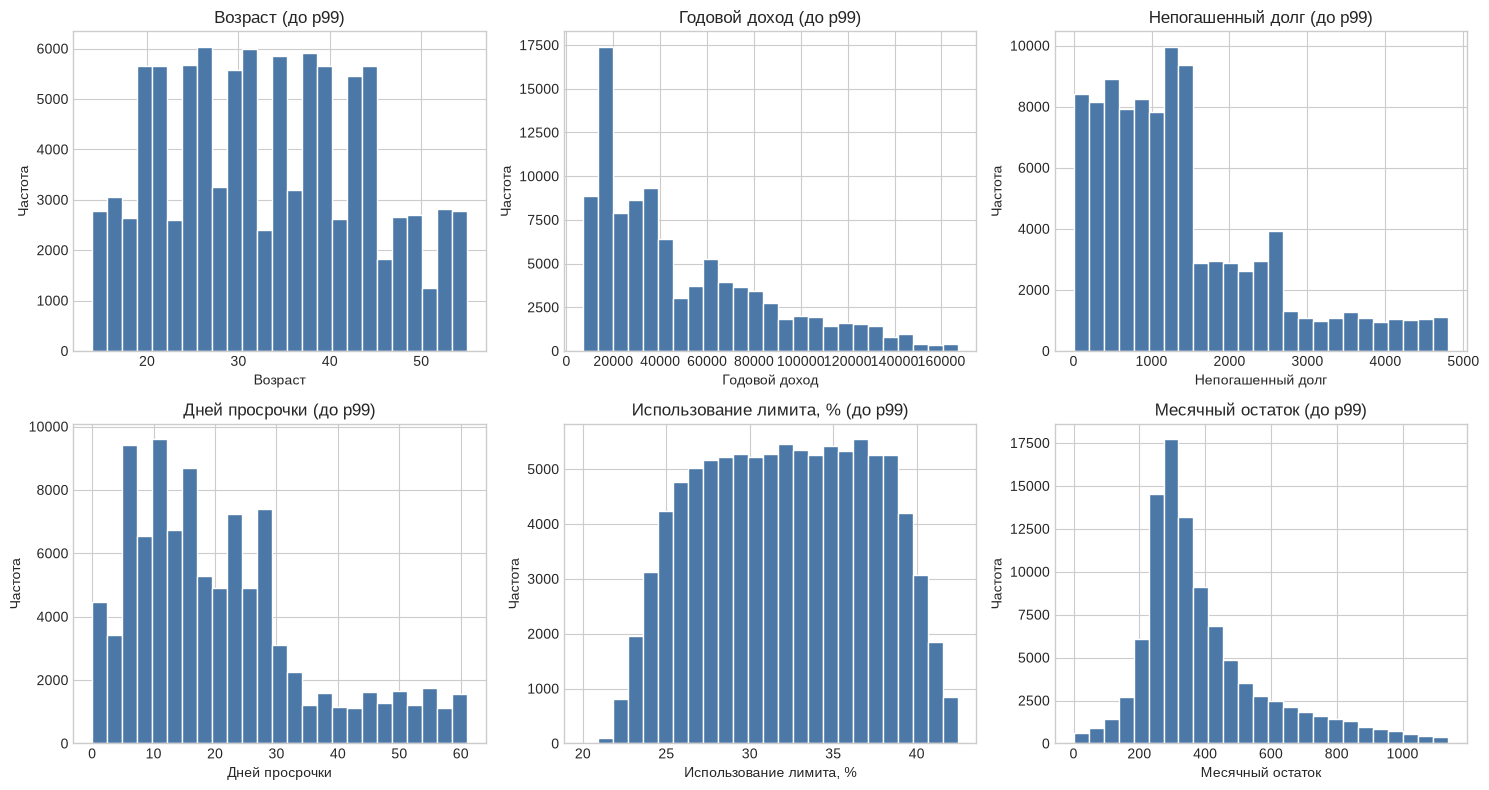

In [15]:
columns_to_plot = [
    ("Age", "Возраст"),
    ("Annual_Income", "Годовой доход"),
    ("Outstanding_Debt", "Непогашенный долг"),
    ("Delay_from_due_date", "Дней просрочки"),
    ("Credit_Utilization_Ratio", "Использование лимита, %"),
    ("Monthly_Balance", "Месячный остаток"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (column, title) in zip(axes.flat, columns_to_plot):
    values = train_clean[column]
    upper = values.quantile(0.99)
    ax.hist(values[values <= upper], bins=25, color="#4c78a8", edgecolor="white")
    ax.set_title(title + " (до p99)")
    ax.set_xlabel(title)
    ax.set_ylabel("Частота")
plt.tight_layout()
plt.show()

## 3. Первичная проверка гипотез

Лабораторная посвящена предобработке, поэтому ниже — только описательные сравнения. Они помогают убедиться, что очищенные признаки содержательно связаны с целью; полноценная проверка потребует статистических тестов и валидации модели.

In [16]:
score_order = ["Good", "Standard", "Poor"]
comparison = (
    train_clean.groupby("Credit_Score", observed=True)[
        ["Outstanding_Debt", "Delay_from_due_date", "Interest_Rate",
         "Num_Credit_Inquiries", "EMI_to_Monthly_Income"]
    ]
    .median()
    .reindex(score_order)
)
comparison.round(3)

,Outstanding_Debt,Delay_from_due_date,Interest_Rate,Num_Credit_Inquiries,EMI_to_Monthly_Income
Credit_Score,,,,,
Good,736.47,10.0,7.0,3.0,0.017
Standard,1001.61,18.0,13.0,5.0,0.023
Poor,1945.35,27.0,21.0,8.0,0.035


In [17]:
credit_mix_table = pd.crosstab(
    train_clean["Credit_Mix"], train_clean["Credit_Score"], normalize="index"
).mul(100).reindex(columns=score_order).round(1)
credit_mix_table

Credit_Score,Good,Standard,Poor
Credit_Mix,,,
Bad,1.5,38.4,60.1
Good,48.9,35.2,16.0
Standard,5.7,72.8,21.5


Описательные таблицы поддерживают основные гипотезы: при переходе от `Good` к `Poor` обычно растут долг, задержка, процентная ставка и число кредитных запросов; категория `Bad` имеет существенно большую долю `Poor`. Это ассоциации, а не доказательство причинного эффекта.

### 3.1. Сохранение результата

Сохраняем обе очищенные таблицы. В `test` нет `Credit_Score`, остальные признаки совпадают с `train`.

In [18]:
train_output = Path("credit_score_train_clean.csv")
test_output = Path("credit_score_test_clean.csv")

train_clean.to_csv(train_output, index=False)
test_clean.to_csv(test_output, index=False)

print(f"Сохранено: {train_output.resolve()} ({train_output.stat().st_size / 1024**2:.1f} МБ)")
print(f"Сохранено: {test_output.resolve()} ({test_output.stat().st_size / 1024**2:.1f} МБ)")
display(train_clean.head())

Сохранено: /home/undndnwnkk/dev/university-works/data-analysis-3rd-course/credit_score_train_clean.csv (34.6 МБ)
Сохранено: /home/undndnwnkk/dev/university-works/data-analysis-3rd-course/credit_score_test_clean.csv (17.2 МБ)


,ID,Customer_ID,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,Month_Number,Credit_History_Months,Debt_to_Annual_Income,EMI_to_Monthly_Income,Investment_to_Monthly_Income,Age_Group,Delay_Band
0,0x1602,CUS_0xd40,January,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,11.27,4,Good,809.98,26.822620,No,49.574949,80.415295,High_spent_Small_value_payments,312.494089,Good,1,265,0.042376,0.027167,0.044067,14–24,1–15 дней
1,0x1603,CUS_0xd40,February,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",0,6,11.27,4,Good,809.98,31.944960,No,49.574949,118.280222,Low_spent_Large_value_payments,284.629162,Good,2,266,0.042376,0.027167,0.064817,14–24,без просрочки
2,0x1604,CUS_0xd40,March,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,11.27,4,Good,809.98,28.609352,No,49.574949,81.699521,Low_spent_Medium_value_payments,331.209863,Good,3,267,0.042376,0.027167,0.044771,14–24,1–15 дней
3,0x1605,CUS_0xd40,April,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5,4,6.27,4,Good,809.98,31.377862,No,49.574949,199.458074,Low_spent_Small_value_payments,223.451310,Good,4,268,0.042376,0.027167,0.109301,14–24,1–15 дней
4,0x1606,CUS_0xd40,May,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6,6,11.27,4,Good,809.98,24.797347,No,49.574949,41.420153,High_spent_Medium_value_payments,341.489231,Good,5,269,0.042376,0.027167,0.022698,14–24,1–15 дней


## Вывод

В работе подготовлены обучающая и тестовая части набора Credit Score Classification.

1. Исходная структура сохранена: 100 000 строк `train` и 50 000 строк `test`; строки не удалялись.
2. Исправлены числовые строки с `_`, технические категории и обычные пропуски.
3. Невозможные значения признаны ошибками ввода, а не реальными выбросами: возраст в тысячи лет, сотни карт и счетов, огромные ставки и отрицательная числовая заглушка баланса исключены до заполнения.
4. Повторные месячные наблюдения использованы для восстановления стабильных характеристик клиента. Профили и статистики заполнения рассчитаны только на `train`, без целевой переменной.
5. Кредитная история переведена в месяцы с сохранением временной логики; для асимметричных месячных показателей использованы медианы.
6. `Name` и `SSN` удалены из-за приватности и отсутствия содержательной ценности. `ID` оставлен только как ключ и должен быть исключён перед обучением.
7. Добавлены интерпретируемые отношения нагрузки и категории возраста/просрочки. Итоговые таблицы не содержат пропусков и имеют одинаковый набор предикторов.

Ограничение: границы аномалий заданы предметно и должны быть согласованы с владельцем данных перед промышленным применением. На следующем этапе следует построить пайплайн кодирования категорий, разделить данные **по клиентам**, а не по строкам, и сравнить модели с учётом дисбаланса классов.